# 06 — VaR / ES and Backtesting

One-day VaR and Expected Shortfall at 95% and 99% for three portfolios from notebook 05: **60/40**, **Equal Weight** and the volatility-targeted **Risk Parity\*** (~4× levered bonds).

**Position-based:** each month the current target weights (× leverage) are applied to the full daily history of asset returns, so every forecast reflects what is held now; only data before the forecast day is used.

| Model | 1-day loss distribution |
|---|---|
| Historical | empirical quantile of the last 500 days |
| Normal | $\sigma$ from the last 250 days, $\mu=0$ |
| EWMA | RiskMetrics $\lambda=0.94$, normal |
| GARCH-t | GARCH(1,1) refit monthly on ≤1000 days; Student-t with $\nu$ from residual kurtosis |
| FHS | GARCH volatility × empirical quantile of standardised residuals (filtered historical simulation) |

**Backtests** on realised net returns, 2010-05-03 → 2026-09-30 (4,272 days):

* Kupiec: $LR_{uc}=-2\ln\frac{(1-p)^{n-x}p^x}{(1-\hat\pi)^{n-x}\hat\pi^x}\sim\chi^2_1$ — right number of exceptions?
* Christoffersen: first-order Markov test of independence $\sim\chi^2_1$ — do exceptions cluster?; conditional coverage $LR_{uc}+LR_{ind}\sim\chi^2_2$.
* Basel traffic light: exceptions of the 99% VaR in rolling 250-day windows (green ≤ 4, yellow 5–9, red ≥ 10).
* ES check: mean of realised loss / forecast ES on exception days (≈ 1 if the tail is right).

**Hypothesis (from notebook 03):** risk forecasts lag shocks, so unconditional models (Historical, Normal) will fail the independence test; conditional models (EWMA, GARCH-t, FHS) will pass more often.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import backtest as B, optimize as O, risk as K, universe as U, var as V

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
PROC = ROOT / "data" / "processed"
asset_daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col=0, parse_dates=True)[U.ASSETS].loc["2007-04-12":]
nets = pd.read_csv(PROC / "backtest_daily_net.csv", index_col=0, parse_dates=True)           # notebook 05
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col=0, parse_dates=True)[U.ASSETS].dropna()
fc = K.load_forecasts(PROC / "cov_forecasts.npz")
paths = O.weight_paths(fc, weekly, cache_dir=PROC / "weights")
lev_rp = B.vol_target_leverage(paths["RiskParity"], fc["cov1w"]["GARCH-CCC"], paths["60/40"])
PORTS = {"60/40": ("var_6040.pkl", paths["60/40"], None, "60/40"),
         "EW": ("var_EW.pkl", paths["EW"], None, "EW"),
         "RiskParity*": ("var_RiskParity_vt.pkl", paths["RiskParity"], lev_rp, "RiskParity*")}
fcs, losses = {}, {}
for name, (f, tg, lev, col) in PORTS.items():
    fcs[name] = V.cached_forecasts(PROC / "var" / f, asset_daily, tg, lev)    # ≈90 s each on first run
    losses[name] = -nets[col]
print({k: (v.index[0].strftime("%Y-%m-%d"), v.index[-1].strftime("%Y-%m-%d"), len(v)) for k, v in fcs.items()})

{'60/40': ('2010-05-03', '2026-09-30', 4272), 'EW': ('2010-05-03', '2026-09-30', 4272), 'RiskParity*': ('2010-05-03', '2026-09-30', 4272)}


## 1. What the forecasts look like (60/40, 99%)

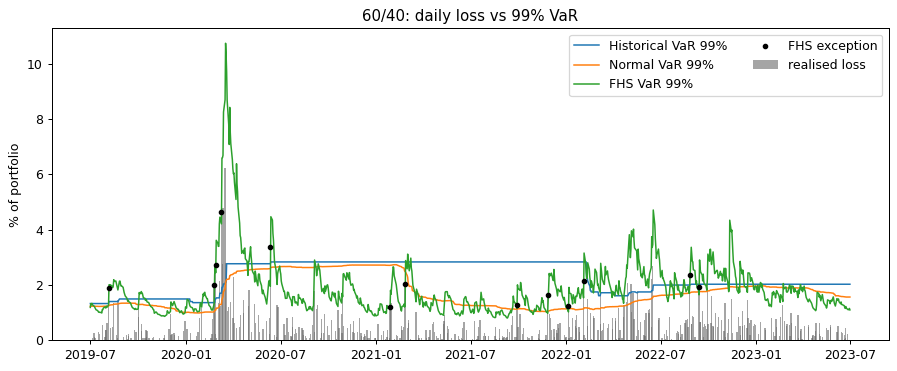

In [2]:
f, L = fcs["60/40"], losses["60/40"]
win = slice("2019-07-01", "2023-06-30")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(L.loc[win].index, L.loc[win].clip(lower=0) * 100, width=2.5, color="dimgrey", alpha=0.6, label="realised loss")
for m in ["Historical", "Normal", "FHS"]:
    ax.plot(f.loc[win, (m, 0.99, "VaR")] * 100, lw=1.2, label=f"{m} VaR 99%")
hit = L.loc[win] > f.loc[win, ("FHS", 0.99, "VaR")]
ax.scatter(L.loc[win][hit].index, L.loc[win][hit] * 100, color="k", s=12, zorder=5, label="FHS exception")
ax.set_ylabel("% of portfolio"); ax.set_title("60/40: daily loss vs 99% VaR"); ax.legend(ncol=2); plt.show()

## 2. Backtest results

In [3]:
tabs = {name: V.backtest_table(losses[name], fcs[name]) for name in PORTS}
res = pd.concat(tabs, names=["portfolio", "model", "level"])
res["pass (all p > 5%)"] = (res[["Kupiec p", "Christoffersen p", "cond. coverage p"]] > 0.05).all(axis=1)
res[["exceptions", "expected", "rate %", "Kupiec p", "Christoffersen p", "cond. coverage p", "loss / ES on exceptions", "pass (all p > 5%)"]]

exceptions  ...  pass (all p > 5%)
portfolio   model      level              ...                   
60/40       Historical 95%       206.000  ...              False
                       99%        62.000  ...              False
            Normal     95%       212.000  ...              False
                       99%        96.000  ...              False
            EWMA       95%       221.000  ...               True
                       99%        96.000  ...              False
            GARCH-t    95%       241.000  ...               True
                       99%        74.000  ...              False
            FHS        95%       214.000  ...               True
                       99%        48.000  ...              False
EW          Historical 95%       216.000  ...              False
                       99%        52.000  ...              False
            Normal     95%       188.000  ...              False
                       99%        79.000  ...              False
            EWMA       95%       217.000  ...               True
                       99%        84.000  ...              False
            GARCH-t    95%       217.000  ...               True
                       99%        59.000  ...              False
            FHS        95%       214.000  ...               True
                       99%        54.000  ...              False
RiskParity* Historical 95%       228.000  ...              False
                       99%        54.000  ...              False
            Normal     95%       209.000  ...              False
                       99%        76.000  ...              False
            EWMA       95%       229.000  ...              False
                       99%        81.000  ...              False
            GARCH-t    95%       252.000  ...              False
                       99%        67.000  ...              False
            FHS        95%       238.000  ...              False
                       99%        54.000  ...               True

[30 rows x 8 columns]

In [4]:
res.groupby(["model", "level"])["pass (all p > 5%)"].sum().unstack().rename(columns=lambda c: f"portfolios passing at {c}").loc[V.MODELS]

level,portfolios passing at 95%,portfolios passing at 99%
model,,
Historical,0,0
Normal,0,0
EWMA,2,0
GARCH-t,2,0
FHS,2,1


## 3. Basel traffic light (99% VaR, rolling 250 days)

In [5]:
tl = {(p, m): V.traffic_light(losses[p], fcs[p][(m, 0.99, "VaR")]) for p in PORTS for m in V.MODELS}
(pd.DataFrame(tl).T * 100).round(1).rename(columns=lambda c: f"% windows {c}")

% windows green  % windows yellow  % windows red
60/40       Historical           60.300            29.500         10.200
            Normal               42.100            38.600         19.400
            EWMA                 34.000            57.700          8.300
            GARCH-t              53.200            43.900          2.900
            FHS                  82.400            17.600          0.000
EW          Historical           73.600            19.100          7.400
            Normal               54.500            30.200         15.300
            EWMA                 47.200            46.900          6.000
            GARCH-t              72.100            27.900          0.000
            FHS                  77.600            22.400          0.000
RiskParity* Historical           74.400            21.300          4.400
            Normal               61.000            30.100          8.900
            EWMA                 53.300            45.200          1.500
            GARCH-t              73.500            25.100          1.400
            FHS                  83.600            15.000          1.400

## 4. When do the exceptions happen?

99% exceptions per calendar year — clustering in 2020 and 2022 is what the independence test punishes.

In [6]:
hits = {m: (losses["60/40"] > fcs["60/40"][(m, 0.99, "VaR")]).groupby(fcs["60/40"].index.year).sum() for m in V.MODELS}
pd.DataFrame(hits).T

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Historical,0,7,0,0,6,9,2,0,7,2,10,0,7,0,3,8,1
Normal,2,8,0,5,7,9,2,4,12,4,12,2,15,0,4,8,2
EWMA,3,6,3,3,6,8,4,6,8,4,11,6,9,3,6,7,3
GARCH-t,1,7,1,4,4,10,3,3,6,3,7,4,5,2,4,7,3
FHS,2,7,1,0,2,8,2,2,3,1,4,4,4,0,1,4,3


In [7]:
hits_rp = {m: (losses["RiskParity*"] > fcs["RiskParity*"][(m, 0.99, "VaR")]).groupby(fcs["RiskParity*"].index.year).sum() for m in V.MODELS}
pd.DataFrame(hits_rp).T

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Historical,0,4,2,4,1,8,1,0,3,3,9,1,8,0,1,4,5
Normal,3,3,3,5,6,7,2,1,6,3,8,3,14,0,1,5,6
EWMA,3,2,3,6,5,6,4,3,5,2,9,4,9,2,3,7,8
GARCH-t,2,2,3,4,4,6,3,2,4,3,8,3,7,2,2,5,7
FHS,2,2,3,4,4,4,1,1,2,3,8,2,5,1,2,4,6


## 5. Accuracy vs conservatism

A model can pass by being too high. Average 99% VaR (capital it would require) next to its exception rate:

In [8]:
cons = {}
for p in PORTS:
    for m in V.MODELS:
        v = fcs[p][(m, 0.99, "VaR")]
        cons[(p, m)] = {"mean VaR99 %": 100 * v.mean(), "exception rate %": 100 * (losses[p].reindex(v.index) > v).mean(),
                        "VaR99 / realised 99% quantile": v.mean() / np.quantile(losses[p].reindex(v.index), 0.99)}
pd.DataFrame(cons).T

mean VaR99 %  ...  VaR99 / realised 99% quantile
60/40       Historical         1.748  ...                          1.000
            Normal             1.386  ...                          0.793
            EWMA               1.306  ...                          0.747
            GARCH-t            1.396  ...                          0.798
            FHS                1.545  ...                          0.884
EW          Historical         1.040  ...                          1.023
            Normal             0.845  ...                          0.832
            EWMA               0.811  ...                          0.798
            GARCH-t            0.881  ...                          0.867
            FHS                0.902  ...                          0.888
RiskParity* Historical         1.549  ...                          0.955
            Normal             1.330  ...                          0.820
            EWMA               1.288  ...                          0.794
            GARCH-t            1.383  ...                          0.853
            FHS                1.445  ...                          0.891

[15 rows x 3 columns]

## Hypothesis — verdict and takeaways

**Confirmed.** The unconditional models fail the independence test in all six portfolio × level cases (Christoffersen p < 0.01): Historical simulation even gets the *number* of 95% exceptions right (206 vs 214 expected for 60/40) but they arrive in clusters (2011, 2015, 2018, 2020, 2022). Conditional models pass far more often at 95%.

* **FHS is the most reliable model** — answer to README question 5. It passes every test at 95% for 60/40 (214 exceptions vs 213.6 expected, conditional-coverage p = 0.43) and EW; at 99% its exception rate (1.1–1.3%) passes Kupiec for all three portfolios, it never enters the Basel red zone for 60/40 and EW, and realised loss / forecast ES on exception days is 1.03 — the tail size is right, not only the quantile.
* **The 99% level is where models separate.** Normal and EWMA give ~2× the expected 99% exceptions and understate ES by 20–30% (loss/ES ≈ 1.2–1.3): fat tails, not volatility dynamics, are the problem there. GARCH-t fixes the dynamics but the moment-based ν is too high (tails still too thin, 1.4–1.7% exceptions); using the empirical residuals (FHS) instead of a parametric t is what closes the gap.
* **Conservative ≠ accurate.** Historical simulation demands the most capital (mean 99% VaR 1.75% for 60/40 vs 1.55% for FHS) and still produces more exceptions (62 vs 48) because it reacts late.
* **Leverage makes risk harder to measure.** For the volatility-targeted risk parity portfolio (~4× bonds) every model fails at 95%; only FHS passes at 99%. Its exceptions bunch in 2020, 2022 and 2026 — the bond-volatility regimes notebook 05 identified.
* **Caveat:** forecasts use target weights (no intra-month drift) and daily returns mix New York, Frankfurt and Tokyo closes; both add noise but affect all models equally.

Next: notebook 07 — historical stress tests on the fixed windows in `data/metadata/stress_periods.csv`.